In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def expan(img, cmin, cmax):
    salida = np.zeros_like(img, dtype=np.uint8)
    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            ND = img[i, j]
            if ND <= cmin:
                salida[i, j] = 0
            elif ND >= cmax:
                salida[i, j] = 255
            else:
                salida[i, j] = int(((ND - cmin) * 255) / (cmax - cmin))
    return salida

In [ ]:
def corte(img, porc):
    hist = cv2.calcHist([img], [0], None, [256], [0,256]).ravel().astype(int)
    total_pix = img.size
    corte_pix = int(total_pix * porc)

    acumulado = 0
    cmin = 0
    for i in range(256):
        acumulado += hist[i]
        if acumulado > corte_pix:
            cmin = i
            break

    acumulado = 0
    cmax = 255
    for i in range(255, -1, -1):
        acumulado += hist[i]
        if acumulado > corte_pix:
            cmax = i
            break

    return expan(img, cmin, cmax)

def corte_rgb_from_channels(b, g, r, porc=0.01):
    b_corte = corte(b, porc)
    g_corte = corte(g, porc)
    r_corte = corte(r, porc)
    return cv2.merge([b_corte, g_corte, r_corte])

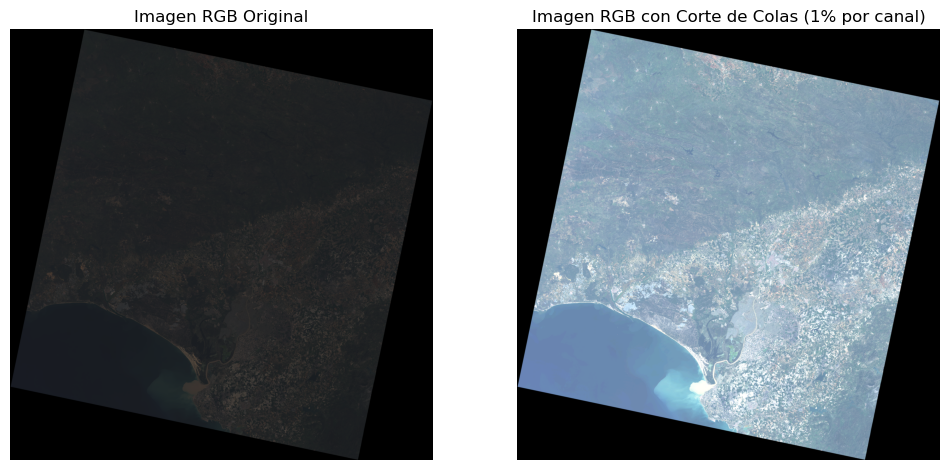

In [5]:
b = cv2.imread("RGB/Landsat_C_02-11_B.png", cv2.IMREAD_GRAYSCALE)
g = cv2.imread("RGB/Landsat_C_03-11_G.png", cv2.IMREAD_GRAYSCALE)
r = cv2.imread("RGB/Landsat_C_04-11_R.png", cv2.IMREAD_GRAYSCALE)

img_rgb = cv2.merge([b, g, r])
img_rgb_corte = corte_rgb_from_channels(b, g, r, porc=0.01)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_rgb_corte, cv2.COLOR_BGR2RGB))
plt.title("Imagen RGB con Corte de Colas (1% por canal)")
plt.axis("off")
plt.show()